In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

# Machine Learning & Preprocessing
from sklearn.preprocessing import PowerTransformer, StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# SMOTE for imbalanced classes
from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import files
import pandas as pd

# Step 1: This will create a "Choose Files" button
uploaded = files.upload()

# Step 2: This loads the file you just selected
df = pd.read_csv('disease_diagnosis.csv')

# Step 3: Show the data!
df.head()

Saving disease_diagnosis.csv to disease_diagnosis.csv


,Patient_ID,Age,Gender,Symptom_1,Symptom_2,Symptom_3,Heart_Rate_bpm,Body_Temperature_C,Blood_Pressure_mmHg,Oxygen_Saturation_%,Diagnosis,Severity,Treatment_Plan
0,1,74,Male,Fatigue,Sore throat,Fever,69,39.4,132/91,94,Flu,Moderate,Medication and rest
1,2,66,Female,Sore throat,Fatigue,Cough,95,39.0,174/98,98,Healthy,Mild,Rest and fluids
2,3,32,Male,Body ache,Sore throat,Fatigue,77,36.8,136/60,96,Healthy,Mild,Rest and fluids
3,4,21,Female,Shortness of breath,Headache,Cough,72,38.9,147/82,99,Healthy,Mild,Rest and fluids
4,5,53,Male,Runny nose,Sore throat,Fatigue,100,36.6,109/106,92,Healthy,Mild,Rest and fluids


In [ ]:
# Strip any random spaces from text columns
df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

# Split Blood Pressure into distinct numerical columns
df[['BP_Systolic', 'BP_Diastolic']] = df['Blood_Pressure_mmHg'].str.split('/', expand=True).astype(float)

# Drop irrelevant/leaky columns
df_cleaned = df.drop(['Patient_ID', 'Blood_Pressure_mmHg', 'Treatment_Plan'], axis=1)

In [ ]:
# STEP 2: FIX SKEWNESS ON NUMERICAL DATA
# ==========================================
print("2. Fixing Skewness via PowerTransformer...")
num_cols = ['Age', 'Heart_Rate_bpm', 'Body_Temperature_C', 'Oxygen_Saturation_%', 'BP_Systolic', 'BP_Diastolic']

# We use Yeo-Johnson as it handles zero and negative values automatically
pt = PowerTransformer(method='yeo-johnson')
df_cleaned[num_cols] = pt.fit_transform(df_cleaned[num_cols])

2. Fixing Skewness via PowerTransformer...


In [ ]:
# STEP 3: FEATURE ENGINEERING (Categorical to Numeric)
# ==========================================
print("3. Feature Engineering...")

# A. Symptom Multi-Hot Encoding
symptom_cols = ['Symptom_1', 'Symptom_2', 'Symptom_3']
all_sym = pd.unique(df_cleaned[symptom_cols].values.ravel('K'))
all_sym = [s for s in all_sym if pd.notnull(s)] # Remove blanks

# Generate 0s and 1s for every unique symptom
for sym in all_sym:
    df_cleaned[f'Sym_{sym}'] = df_cleaned[symptom_cols].apply(lambda row: 1 if sym in row.values else 0, axis=1)

df_cleaned = df_cleaned.drop(symptom_cols, axis=1) # Drop old columns

# B. Map Ordinal / Binary text to numbers
df_cleaned['Gender'] = df_cleaned['Gender'].map({'Male': 1, 'Female': 0})
df_cleaned['Severity'] = df_cleaned['Severity'].map({'Mild': 1, 'Moderate': 2, 'Severe': 3})

# C. Encode Target Variable (Diagnosis)
le = LabelEncoder()
y = le.fit_transform(df_cleaned['Diagnosis'])
X = df_cleaned.drop('Diagnosis', axis=1)

3. Feature Engineering...


In [ ]:
# STEP 4: TRAIN-TEST SPLIT & SMOTE ON TRAINING
# ==========================================
print("4. Applying SMOTE to fix Imbalance...")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Apply SMOTE strictly on the Training Set to prevent data leakage!
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

4. Applying SMOTE to fix Imbalance...


In [ ]:
# STEP 5: FEATURE SCALING
# ==========================================
print("5. Scaling Data...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)

# Convert scaled train array back to DataFrame for Feature Importance plotting later
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)

5. Scaling Data...


In [ ]:
# STEP 6: MODEL TRAINING (Grid Search & CV)
# ==========================================
print("6. Training All 4 Models using GridSearchCV...")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define the models and parameters
model_params = {
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {'n_estimators': [100, 200], 'max_depth': [10, 20, None]}
    },
    'Logistic Regression': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'params': {'C': [0.1, 1.0, 10.0]}
    },
    'SVM': {
        'model': SVC(random_state=42),
        'params': {'C': [0.1, 1.0, 10.0], 'kernel': ['linear', 'rbf']}
    },
    'Naive Bayes': {
        'model': GaussianNB(),
        'params': {'var_smoothing': [1e-9, 1e-8]} # Standard params for GaussianNB
    }
}

best_models = {}

for name, config in model_params.items():
    print(f"   -> Tuning {name}...")

    gs = GridSearchCV(
        config['model'],
        config['params'],
        cv=cv,
        scoring='f1_macro',
        n_jobs=-1
    )
    # Note: Using X_train_scaled_df instead of X_train_scaled keeps column names for feature importance later
    gs.fit(X_train_scaled_df, y_train_res)

    best_models[name] = gs.best_estimator_
    print(f"      Best Macro F1 CV Score: {gs.best_score_:.4f}")

6. Training All 4 Models using GridSearchCV...
   -> Tuning Random Forest...
      Best Macro F1 CV Score: 1.0000
   -> Tuning Logistic Regression...
      Best Macro F1 CV Score: 0.9876
   -> Tuning SVM...
      Best Macro F1 CV Score: 0.9884
   -> Tuning Naive Bayes...
      Best Macro F1 CV Score: 0.9906


In [ ]:
# STEP 7: EVALUATION & VISUALIZATION
# ==========================================
print("\n7. Final Evaluation for All Models...")

# Iterate through all saved best models and print their performance
for name, model in best_models.items():
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    print(f"\n--- {name.upper()} ---")
    print(f"Test Accuracy: {acc * 100:.2f}%")
    print(classification_report(y_test, y_pred, target_names=le.classes_))






7. Final Evaluation for All Models...

--- RANDOM FOREST ---
Test Accuracy: 100.00%
              precision    recall  f1-score   support

  Bronchitis       1.00      1.00      1.00        67
        Cold       1.00      1.00      1.00        33
         Flu       1.00      1.00      1.00        58
     Healthy       1.00      1.00      1.00       233
   Pneumonia       1.00      1.00      1.00         9

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400


--- LOGISTIC REGRESSION ---
Test Accuracy: 97.00%
              precision    recall  f1-score   support

  Bronchitis       1.00      1.00      1.00        67
        Cold       0.80      0.85      0.82        33
         Flu       1.00      1.00      1.00        58
     Healthy       0.98      0.97      0.97       233
   Pneumonia       1.00      1.00      1.00         9

    accuracy                           0.97      


Generating Feature Importance Plot (Random Forest)...


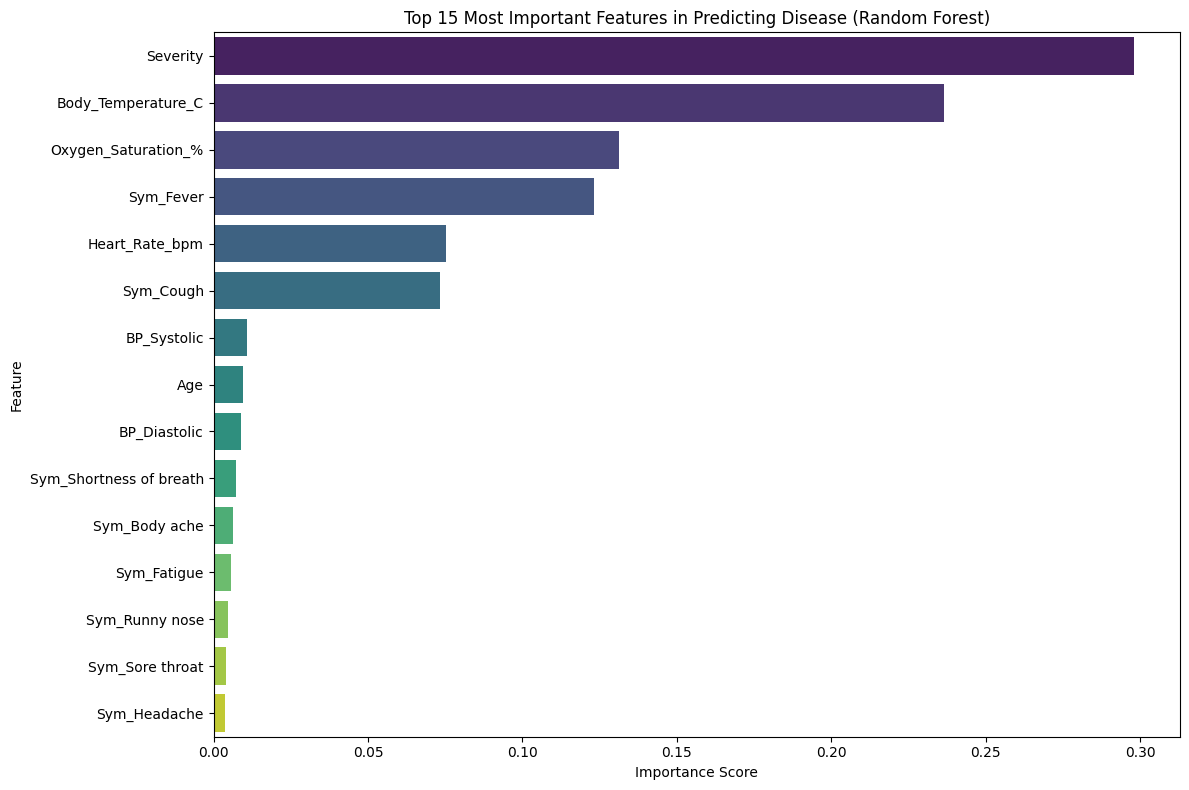

In [ ]:
# VISUALIZATION 1: Feature Importance (Only possible for Random Forest)
print("\nGenerating Feature Importance Plot (Random Forest)...")
rf_best = best_models['Random Forest']
feat_imp = pd.Series(rf_best.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x=feat_imp.head(15).values, y=feat_imp.head(15).index, palette='viridis')
plt.title('Top 15 Most Important Features in Predicting Disease (Random Forest)')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()



Generating 2x2 Grid of Confusion Matrices...


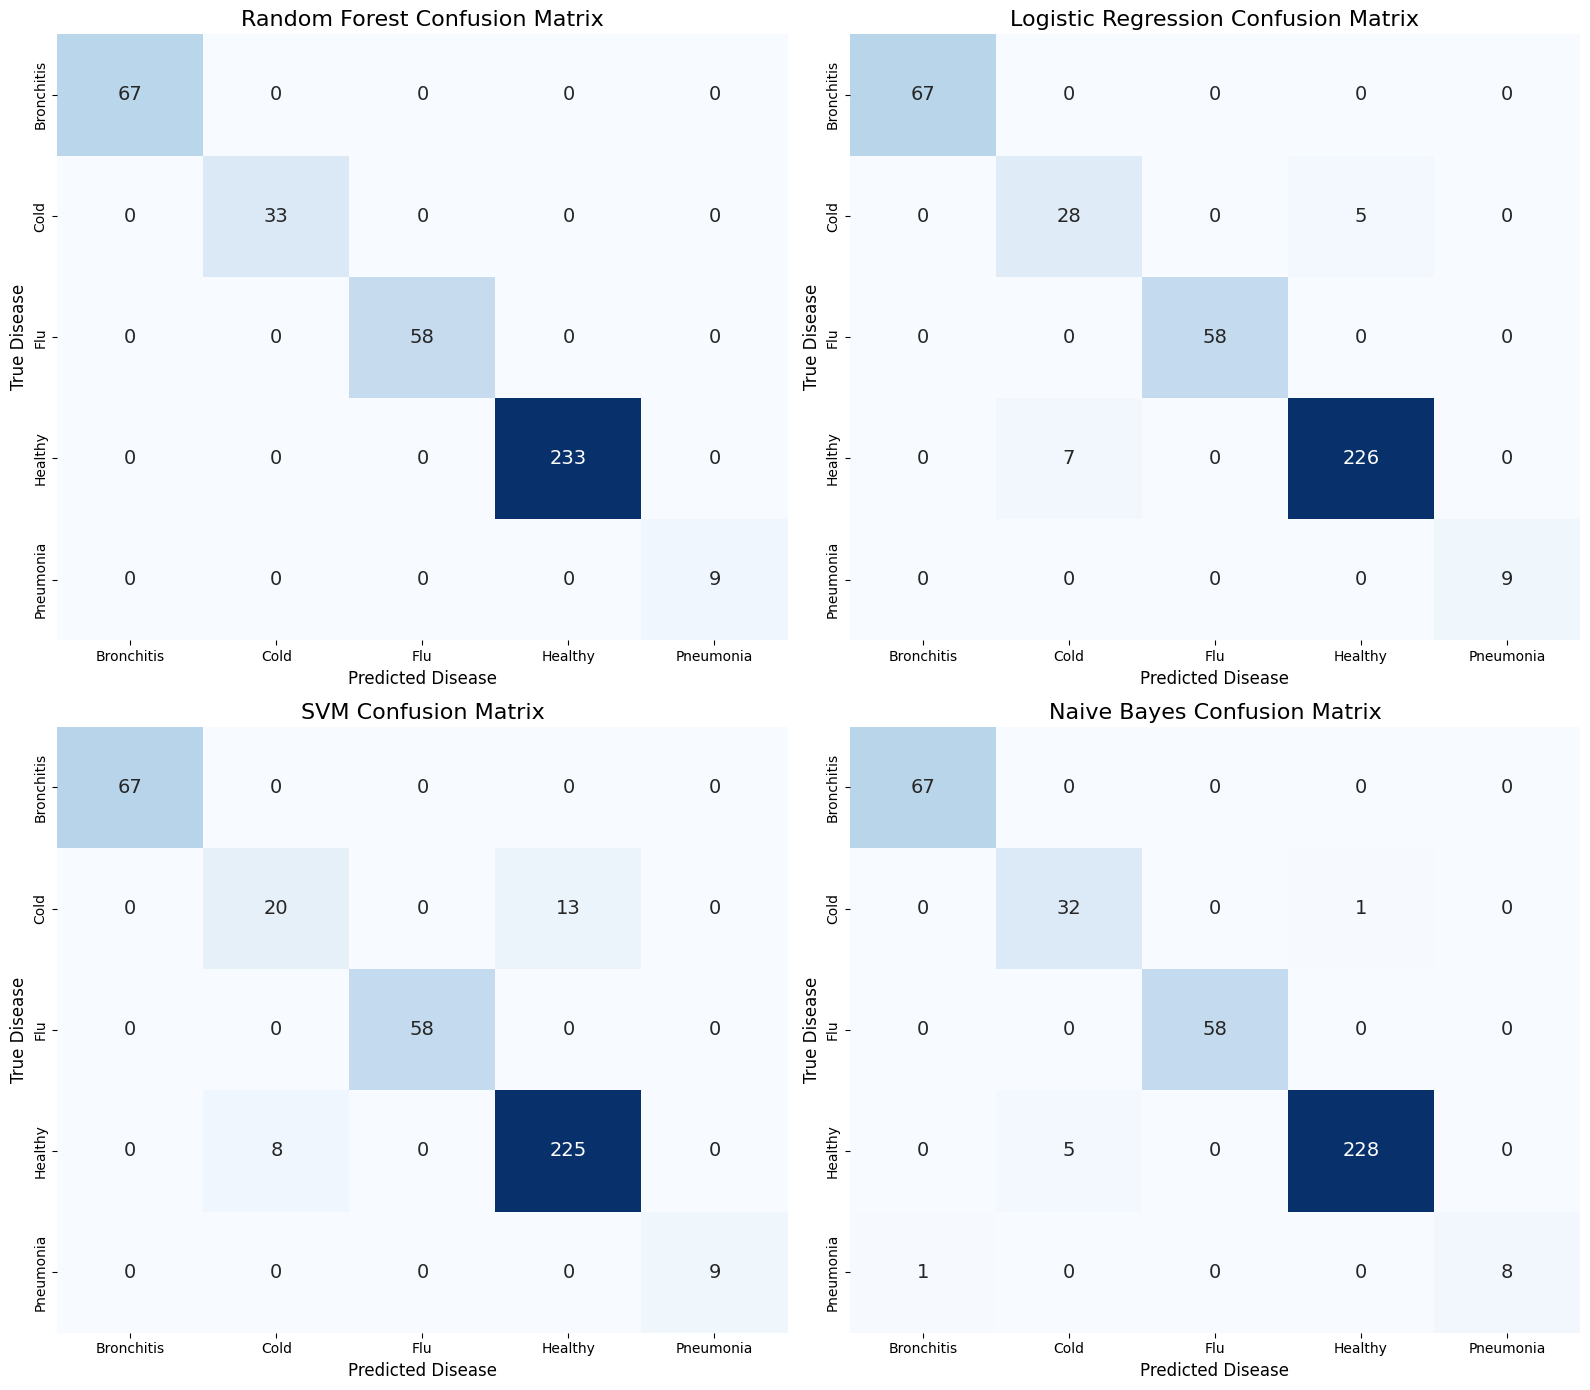

In [ ]:
# ==========================================
# STEP 7: EVALUATION (ALL CONFUSION MATRICES)
# ==========================================
print("Generating 2x2 Grid of Confusion Matrices...")

# Create a 2x2 grid for subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten() # Flatten the 2x2 grid so we can loop through it easily

# Iterate through your trained models
for idx, (name, model) in enumerate(best_models.items()):

    # Make predictions for the specific model
    y_pred = model.predict(X_test_scaled)

    # Calculate its confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Plot it onto the corresponding square in the 2x2 grid
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=le.classes_, yticklabels=le.classes_,
                ax=axes[idx], cbar=False, annot_kws={"size": 14})

    axes[idx].set_title(f'{name} Confusion Matrix', fontsize=16)
    axes[idx].set_ylabel('True Disease', fontsize=12)
    axes[idx].set_xlabel('Predicted Disease', fontsize=12)

# Adjust layout to make sure text doesn't overlap, then show the plot
plt.tight_layout()
plt.show()

In [ ]:
import joblib

# 1. Choose the model you want to save (Random Forest performed the best)
final_model = best_models['Random Forest']

# 2. Save the Model
joblib.dump(final_model, 'disease_prediction_rf_model.pkl')

# 3. Save the Scaler (needed to scale new incoming data)
joblib.dump(scaler, 'scaler.pkl')

# 4. Save the Label Encoder (needed to convert the numeric prediction back to a disease name)
joblib.dump(le, 'label_encoder.pkl')

print("Model and preprocessors saved successfully!")

Model and preprocessors saved successfully!


In [ ]:
import joblib

# ... (previous saving code) ...

# Save the PowerTransformer (fixes skewness)
joblib.dump(pt, 'power_transformer.pkl')

# Save the exact column order of your training data
joblib.dump(X.columns.tolist(), 'model_columns.pkl')

print("All files saved successfully!")

All files saved successfully!
